In [1]:
#  Exploring GDP per capita (Maddison Project)
# Reads: ../data/gdp-per-capita-maddison-project-database.csv 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
sns.set_theme(style="whitegrid")

In [3]:
# Load
gdp = pd.read_csv(r"C:\Users\admin\Desktop\Captoneproject-pydata\data\gdp-per-capita-maddison-project-database.csv")
print("Original columns:", gdp.columns.tolist())
gdp = gdp.rename(columns={"GDP per capita": "gdp_pc"})

Original columns: ['Entity', 'Code', 'Year', 'GDP per capita', 'GDP per capita (Annotations)']


In [4]:
    # First look
print("\nHEAD")
display(gdp.head())
print("\nTAIL")
display(gdp.tail())
print("\nSAMPLE")
display(gdp.sample(8, random_state=1))


HEAD


,Entity,Code,Year,gdp_pc,GDP per capita (Annotations)
0,Afghanistan,AFG,1950,1156.0,NaN
1,Afghanistan,AFG,1951,1170.0,NaN
2,Afghanistan,AFG,1952,1189.0,NaN
3,Afghanistan,AFG,1953,1240.0,NaN
4,Afghanistan,AFG,1954,1245.0,NaN



TAIL


,Entity,Code,Year,gdp_pc,GDP per capita (Annotations)
21581,Zimbabwe,ZWE,2018,1900.1992,NaN
21582,Zimbabwe,ZWE,2019,1753.0244,NaN
21583,Zimbabwe,ZWE,2020,1585.9728,NaN
21584,Zimbabwe,ZWE,2021,1687.2532,NaN
21585,Zimbabwe,ZWE,2022,1703.5294,NaN



SAMPLE


,Entity,Code,Year,gdp_pc,GDP per capita (Annotations)
2641,Chad,TCD,2012,1742.6540,NaN
20750,Uruguay,URY,1966,7693.0000,NaN
13272,Paraguay,PRY,1969,2730.0000,NaN
275,Angola,AGO,1997,1687.3177,NaN
9370,Latvia,LVA,2005,17069.6560,NaN
5061,Finland,FIN,1881,1769.0000,NaN
4386,Dominican Republic,DOM,2003,7324.6973,NaN
9716,Libya,LBY,1951,668.0000,NaN


In [5]:
# Structure
print("\nSHAPE (rows, columns)")
print(gdp.shape)
print("\nDTYPES")
print(gdp.dtypes)
print("\nINFO")
gdp.info()
print("\nMISSING VALUES")
print(gdp.isna().sum())
print("\nDUPLICATE ROWS")
print(gdp.duplicated(["Entity", "Year"]).sum())


SHAPE (rows, columns)
(21586, 5)

DTYPES
Entity                              str
Code                                str
Year                              int64
gdp_pc                          float64
GDP per capita (Annotations)        str
dtype: object

INFO
<class 'pandas.DataFrame'>
RangeIndex: 21586 entries, 0 to 21585
Data columns (total 5 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Entity                        21586 non-null  str    
 1   Code                          21387 non-null  str    
 2   Year                          21586 non-null  int64  
 3   gdp_pc                        21586 non-null  float64
 4   GDP per capita (Annotations)  28 non-null     str    
dtypes: float64(1), int64(1), str(3)
memory usage: 1.1 MB

MISSING VALUES
Entity                              0
Code                              199
Year                                0
gdp_pc                              0
GD

In [6]:
# The annotations column is mostly empty, so check what it holds
print("\nANNOTATIONS COLUMN")
print("Non-empty rows:", gdp["GDP per capita (Annotations)"].notna().sum())
print(gdp["GDP per capita (Annotations)"].dropna().unique()[:5])



ANNOTATIONS COLUMN
Non-empty rows: 28
<ArrowStringArray>
['United States, Canada, Australia and New Zealand']
Length: 1, dtype: str


In [9]:
# Separate aggregates (regions) from real countries
is_aggregate = gdp["Code"].isna() | gdp["Code"].astype(str).str.startswith("OWID")
print("Aggregate rows (not countries):", is_aggregate.sum())
print("Country rows:", (~is_aggregate).sum())
print("Some aggregate names:", sorted(gdp.loc[is_aggregate, "Entity"].unique())[:12])
countries = gdp[~is_aggregate].copy()


Aggregate rows (not countries): 652
Country rows: 20934
Some aggregate names: ['Czechoslovakia', 'East Asia (Maddison)', 'Eastern Europe (Maddison)', 'Latin America (Maddison)', 'Middle East and North Africa (Maddison)', 'South and South East Asia (Maddison)', 'Sub Saharan Africa (Maddison)', 'Sudan (former)', 'USSR', 'Western Europe (Maddison)', 'Western offshoots (Maddison)', 'World']


In [10]:
#  Coverage by year: how many countries have data
countries_per_year = countries.groupby("Year")["Entity"].nunique()
print("\nCOUNTRIES WITH DATA (selected years)")
print(countries_per_year.loc[[y for y in [1820, 1900, 1950, 1975, 2000, 2022] if y in countries_per_year.index]])



COUNTRIES WITH DATA (selected years)
Year
1820     54
1900     47
1950    142
1975    149
2000    165
2022    165
Name: Entity, dtype: int64


In [11]:
# Gaps: do countries have missing years in the middle?
since_1950 = countries[countries["Year"] >= 1950].copy()
span = since_1950.groupby("Entity")["Year"].agg(["min", "max", "count"])
span["expected"] = span["max"] - span["min"] + 1
span["gaps"] = span["expected"] - span["count"]
print("\nGAPS IN THE SERIES, 1950 onward")
print("Countries with at least one missing year in the middle:", int((span["gaps"] > 0).sum()))
print(span["count"].describe().round(1))



GAPS IN THE SERIES, 1950 onward
Countries with at least one missing year in the middle: 15
count    165.0
mean      69.9
std        9.0
min       33.0
25%       73.0
50%       73.0
75%       73.0
max       73.0
Name: count, dtype: float64


In [12]:
# Centre and spread
print("\nDESCRIBE (countries only)")
print(countries["gdp_pc"].describe().round(0))

mean_ = countries["gdp_pc"].mean()
median_ = countries["gdp_pc"].median()
std_ = countries["gdp_pc"].std()
skew_ = countries["gdp_pc"].skew()
print(f"\nMean:   {mean_:,.0f}")
print(f"Median: {median_:,.0f}")
print(f"Std:    {std_:,.0f}")
print(f"Skew:   {skew_:.2f}  (positive = tail to the right)")



DESCRIBE (countries only)
count     20934.0
mean       6828.0
std       10760.0
min         295.0
25%        1463.0
50%        2579.0
75%        7088.0
max      160051.0
Name: gdp_pc, dtype: float64

Mean:   6,828
Median: 2,579
Std:    10,760
Skew:   4.16  (positive = tail to the right)



Skew of raw GDP, 1950 onward: 3.16
Skew of log GDP, 1950 onward: 0.12


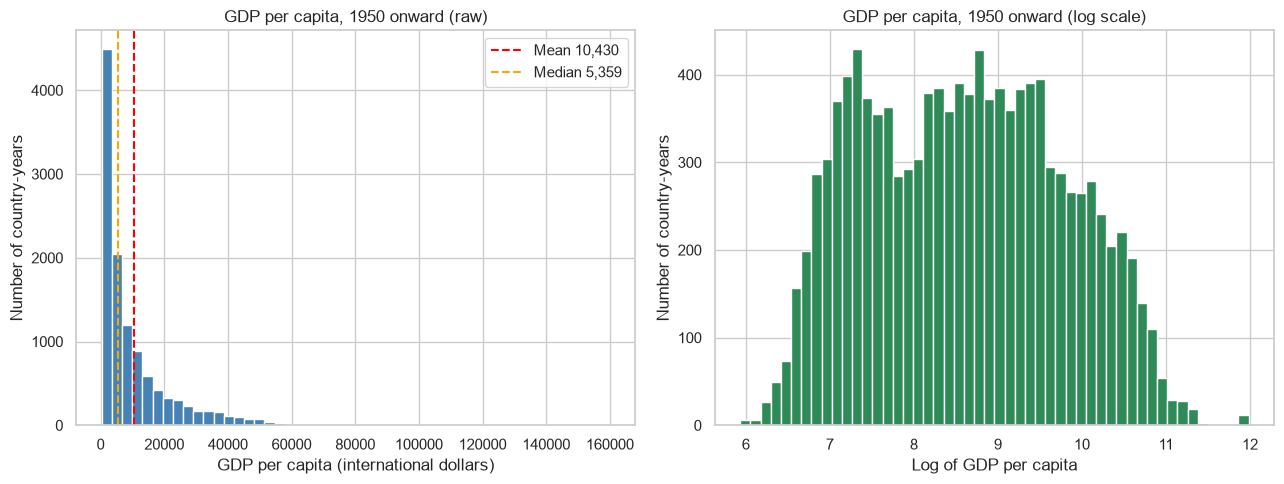

In [13]:
# Raw GDP vs log GDP (use 1950 onward)
since_1950["log_gdp"] = np.log(since_1950["gdp_pc"])
raw_skew = since_1950["gdp_pc"].skew()
log_skew = since_1950["log_gdp"].skew()
print(f"\nSkew of raw GDP, 1950 onward: {raw_skew:.2f}")
print(f"Skew of log GDP, 1950 onward: {log_skew:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(since_1950["gdp_pc"], bins=50, color="steelblue", edgecolor="white")
axes[0].axvline(since_1950["gdp_pc"].mean(), color="red", linestyle="--", label=f"Mean {since_1950['gdp_pc'].mean():,.0f}")
axes[0].axvline(since_1950["gdp_pc"].median(), color="orange", linestyle="--", label=f"Median {since_1950['gdp_pc'].median():,.0f}")
axes[0].set_title("GDP per capita, 1950 onward (raw)")
axes[0].set_xlabel("GDP per capita (international dollars)")
axes[0].set_ylabel("Number of country-years")
axes[0].legend()

axes[1].hist(since_1950["log_gdp"], bins=50, color="seagreen", edgecolor="white")
axes[1].set_title("GDP per capita, 1950 onward (log scale)")
axes[1].set_xlabel("Log of GDP per capita")
axes[1].set_ylabel("Number of country-years")

plt.tight_layout()
plt.show()

GDP per capita (raw) | Continuous | Strongly right-skewed (skew 3.16) | No (87.2% within 1 SD) 

GDP per capita (log) | Continuous | Roughly symmetric, flat-topped (skew 0.12) | Approximately yes (60.8%, 98.8%, 100%) |


### Charts 1 and 2: Distribution of GDP per capita, raw and log (1950 onward)

**What GDP per capita means:** the total value of goods and services a country produces in a year, divided by its population. It is measured in international dollars, which adjust for price differences between countries and over time. It is an average, so it hides inequality inside a country.

**What the charts show:** each bar counts how many country-years (one country in one year) fall in that range. The left chart uses the raw values. The right chart uses the log of the values. The red line is the mean (10,430) and the orange line is the median (5,359).

**Type of distribution (raw):** strongly right-skewed (skew = 3.16). Most country-years have a low GDP per capita, and a few very rich ones stretch a long tail to the right. The mean is far above the median because those rich values pull the average up.

**Type of distribution (log):** roughly symmetric (skew = 0.12), close to a bell shape. It has a flat top and a hint of two humps, so it is not perfectly normal.

**Why I use the log:** income grows by percentages, so equal percentage changes should be equal distances. The log fixes the skew, which suits correlation and hypothesis tests. I will use `log_gdp` in the analysis.

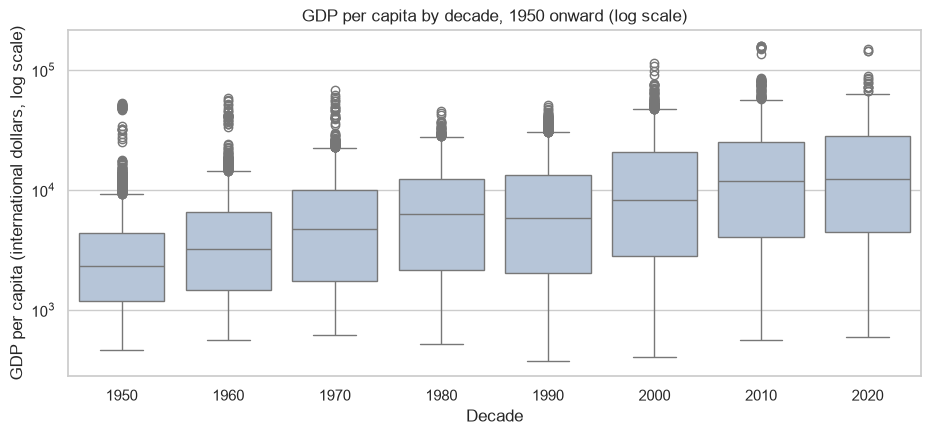

In [26]:
# Spread over time (log scale on the y axis so every decade is readable)
since_1950["decade"] = (since_1950["Year"] // 10) * 10

plt.figure(figsize=(11, 4.5))
sns.boxplot(data=since_1950, x="decade", y="gdp_pc", color="lightsteelblue")
plt.yscale("log")
plt.title("GDP per capita by decade, 1950 onward (log scale)")
plt.xlabel("Decade")
plt.ylabel("GDP per capita (international dollars, log scale)")
plt.show()

### Chart 3: GDP per capita by decade, 1950 onward (log scale)

**What it shows:** each box covers the middle 50% of country-years in a decade, the line inside is the median, the whiskers show the typical range, and the dots are outliers. The y-axis is a log scale, so each step up is a multiplication, not an addition.

**Trend:** the boxes move up over time. The median rises from roughly 2,000 to 3,000 in the 1950s to around 12,000 in the 2020s, so a typical country became much richer.

**A pause:** the median does not rise in every decade. It is slightly lower in the 1990s than in the 1980s. I can see this in the chart, but I have not looked into why.

**Spread:** the boxes are wide in every decade, so countries differ hugely in wealth, and the gap between the richest and poorest countries has stayed large.

**Outliers:** the dots above the boxes are the richest country-years, up to about 100,000 or more. I have not checked which countries they are.

**Caution:** the 2020s box covers only 2020 to 2022.

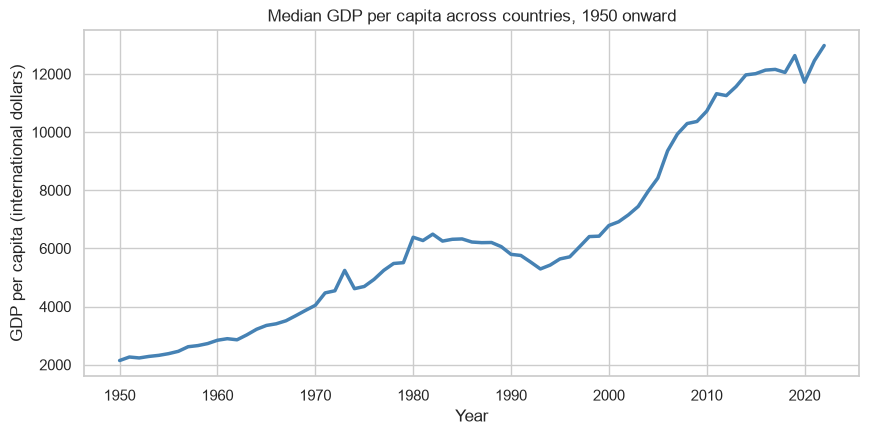

In [27]:

# median GDP per capita by year
median_by_year = since_1950.groupby("Year")["gdp_pc"].median()

plt.figure(figsize=(10, 4.5))
plt.plot(median_by_year.index, median_by_year.values, color="steelblue", linewidth=2.5)
plt.title("Median GDP per capita across countries, 1950 onward")
plt.xlabel("Year")
plt.ylabel("GDP per capita (international dollars)")
plt.show()

## Median GDP per capita across countries, 1950 onward

**What it shows:** each point is the median GDP per capita across all countries in that year. I use the median, not the mean, because GDP is so skewed that a few very rich countries would drag the mean up.

**Trend:** the line rises from about 2,100 in 1950 to about 13,000 in 2022, so the typical country became about six times richer.

**Not a straight line:** growth was slow until the 1970s, there was a flat or falling stretch from the 1980s to the early 1990s, and then growth sped up from the late 1990s. There is also a small dip around 2020 to 2021. The chart shows when these happened, not why.

**Why it matters for my question:** GDP rose across the world over the same years that life expectancy rose and child mortality fell. So part of any link I find could simply come from all of them moving with time.

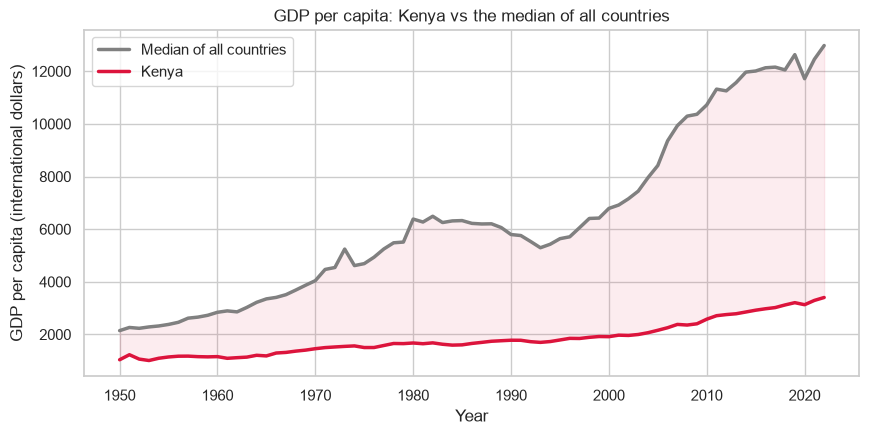

In [25]:
## Kenya vs the median of all countries
kenya = since_1950[since_1950["Entity"] == "Kenya"].set_index("Year")["gdp_pc"]
compare = pd.DataFrame({"Kenya": kenya, "Median of all countries": median_by_year}).dropna()

plt.figure(figsize=(10, 4.5))
plt.plot(compare.index, compare["Median of all countries"], color="gray", linewidth=2.5, label="Median of all countries")
plt.plot(compare.index, compare["Kenya"], color="crimson", linewidth=2.5, label="Kenya")
plt.fill_between(compare.index, compare["Kenya"], compare["Median of all countries"], color="crimson", alpha=0.08)
plt.title("GDP per capita: Kenya vs the median of all countries")
plt.xlabel("Year")
plt.ylabel("GDP per capita (international dollars)")
plt.legend()
plt.show()


###  GDP per capita, Kenya vs the median of all countries

**What it shows:** the grey line is the median of all countries, the red line is Kenya, and the pink band is the gap between them.

**Kenya is below the median in every year since 1950** (all 73 years in the data).

**The gap widens:** in 1950 Kenya's GDP per capita (about 1,040) was roughly half the median (about 2,140). By 2022 it is about 3,400 against a median of about 13,000, so Kenya is at roughly a quarter of the median. Kenya did grow, about 3 times over, but the median grew about 6 times.

**What I cannot say:** the chart shows the gap, not the reasons for it.

**Link to my other charts:** Kenya also had lower life expectancy and higher child mortality than the average in every year. That fits my hypothesis, but one country is only an example, not a test.

**Note:** the grey line is the median across countries, not the world average per person.